# Analysis of pyoverdine peptide chain diversity

This notebook runs through data analysis to explore the peptide chain diversity 
in published pyoverdines.

## Load the data

In [2]:
import pandas as pd

pyoverdine_lib = pd.read_csv(
    "../data/pyoverdine_peptide_chains.csv", encoding="cp1252")
pyoverdine_lib["peptide"] = pyoverdine_lib["peptide"].str.replace("azDab", "Dab")

pyoverdine_lib.head()

,organism,species,strain,sidechain,chromophore,peptide,group,class,reference
0,P. entomophila L48,P. entomophila,L48,Suca,Pyoverdine,Ala-Asn-Dab-OH-His-Gly-Gly-Ala-Thr-Ser-(OH-Orn),1,II,1
1,P. fluorescens 1.3,P. fluorescens,1.3,Suc,Pyoverdine,D-Ala-D-Lys-Gly-Gly-L-OH-Asp-D-Gln/L-Dab-Gly-L...,1,II,2
2,Pseudomonas sp. 3C14,Pseudomonas sp.,3C14,NaN,NaN,Ala-Lys-Gly-Gly-OH-Asp-Gln-Dab-Gly-Ala-(OH-Orn),1,II,3
3,Pseudomonas sp. s3d06,Pseudomonas sp.,s3d06,NaN,NaN,Ala-Val-OH-His-Asp-Cit-Ser-Ala-Ala-(OH-Orn),1,II,3
4,Pseudomonas sp. 3D03,Pseudomonas sp.,3D03,NaN,NaN,Ser-Lys-Ser-Thr-Ala-Ac-OH-Orn-(OH-Orn),1,II,3


## Basic counts

Count the length of each peptide

In [3]:
import re 

TOKEN = re.compile(r"(?:(?![A-Z][a-z]{2}).)*[A-Z][a-z]{2}")

def peptide_length(pep):
    if pd.isna(pep):
        return pd.NA
    return len(TOKEN.findall(pep))

lengths = pyoverdine_lib["peptide"].apply(peptide_length)

lengths.describe()

count    83.000000
mean      8.349398
std       1.692406
min       6.000000
25%       7.000000
50%       8.000000
75%      10.000000
max      14.000000
Name: peptide, dtype: float64

Split the peptides into individual amino acids and count them

In [4]:
STEREO = re.compile(r"(?<![A-Za-z])([DL])-")

def split_peptide(pep):
    if pd.isna(pep):
        return []
    return [t.strip("-()/ ") for t in TOKEN.findall(pep)]

def parse(tok):
    m = STEREO.search(tok)
    return pd.Series({"stereo": m.group(1) if m else "unspecified",
                      "residue": STEREO.sub("", tok)})

res = (pyoverdine_lib["peptide"].apply(split_peptide)
         .explode().dropna()
         .rename_axis("row").reset_index())
res = res.join(res["peptide"].apply(parse))

counts = pd.crosstab(res["residue"], res["stereo"], margins=True, margins_name="Total")

# Double check all OH-Orn is cyclised
cyclic_orn = pyoverdine_lib["peptide"].str.count(r"\((?:[LD]-)?OH-Orn\)").sum()
assert (cyclic_orn == counts.loc["OH-Orn", "Total"])

print(counts)

stereo       D    L  unspecified  Total
residue                                
Ac-OH-Orn   13    8           12     33
Ala         17   17           30     64
Arg          0    1            3      4
Asn          1    1            1      3
Asp          1   16           10     27
Bu-OH-Orn    2    0            0      2
Cit          1    0            1      2
Dab          1    9            6     16
Fo-OH-Orn   12   17           13     42
Fo-Ser       0    0            1      1
Gln          9    4            5     18
Glu          1    2            1      4
Gly          0    0           61     61
Hse          1    8            3     12
Lys         10   29           19     58
OH-Asn       0    0            1      1
OH-Asp      17    8           15     40
OH-His       0    1            2      3
OH-Orn       5   23           18     46
Orn          0    8            8     16
Ser         47   40           72    159
Thr         13   33           23     69
Val          0    1            1      2


## Iron-binding residues

Count the iron binding residues

In [5]:
all = ["OH-Orn", "Ac-OH-Orn", "Fo-OH-Orn", "Bu-OH-Orn", "OH-Asn", "OH-Asp", "OH-His"]
not_orn = ["OH-Asn", "OH-Asp", "OH-His"]
totals_all = res["residue"].value_counts().reindex(all, fill_value=0)
totals_not_orn = res["residue"].value_counts().reindex(not_orn, fill_value=0)

print (f'Percentage of non-Orn residues: {totals_not_orn.sum() / totals_all.sum() * 100 :.3}%')

no_orn = (~pyoverdine_lib["peptide"].str.contains("OH-Orn")).sum()
print (f'There are {no_orn} pyoverdines with no Orn binding residues')

Percentage of non-Orn residues: 26.3%
There are 4 pyoverdines with no Orn binding residues


Graph the residues

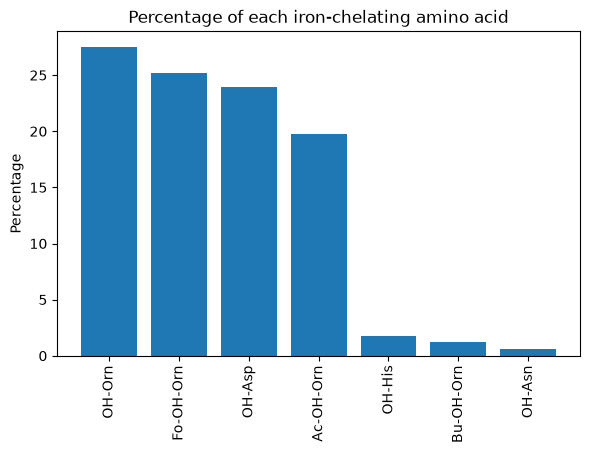

In [6]:
import matplotlib.pyplot as plt

iron_binding_percentages = (totals_all / totals_all.sum() * 100).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(iron_binding_percentages.index, iron_binding_percentages.values)
ax.set_title("Percentage of each iron-chelating amino acid")
ax.set_ylabel("Percentage")
fig.tight_layout()
plt.xticks(rotation=90)
plt.show()

## Amino acids across all peptides

Counts of different subgroups

In [7]:
combined = res["residue"].value_counts()
combined_sum = combined.sum()

# Hydroxyl-containing amino acids
OH = ["Ser", "Thr", "Fo-Ser", "HSe"]
OH_sum = combined.reindex(OH, fill_value=0).sum()
print (f'Percentage of hydroxyl-containing amino acids: {OH_sum / combined_sum * 100 :.3}%')

# Orn sum
orn = ["Orn", "OH-Orn", "Fo-OH-Orn", "Ac-OH-Orn", "Bu-OH-Orn", "Cit"]
orn_sum = combined.reindex(orn, fill_value=0).sum()
print (f'Percentage of Orn-like residues: {orn_sum / combined_sum * 100 :.3}%')

# Small aliphatic 
ali = ["Gly", "Ala", "Val"]
ali_sum = combined.reindex(ali, fill_value=0).sum()
print (f'Percentage of small aliphatic residues: {ali_sum / combined_sum * 100 :.3}%')

# Lysine-like
Lys = ["Lys", "eLys"]
Lys_sum = combined.reindex(Lys, fill_value=0).sum()
print (f'Percentage of Lys-like residues: {Lys_sum / combined_sum * 100 :.2}%')

# Asp-like
Asp = ["Asp", "OH-Asp"]
Asp_sum = combined.reindex(Asp, fill_value=0).sum()
print (f'Percentage of Asp-like residues: {Asp_sum / combined_sum * 100 :.2}%')


Percentage of hydroxyl-containing amino acids: 33.0%
Percentage of Orn-like residues: 20.3%
Percentage of small aliphatic residues: 18.3%
Percentage of Lys-like residues: 9.8%
Percentage of Asp-like residues: 9.7%


Graph of percentages

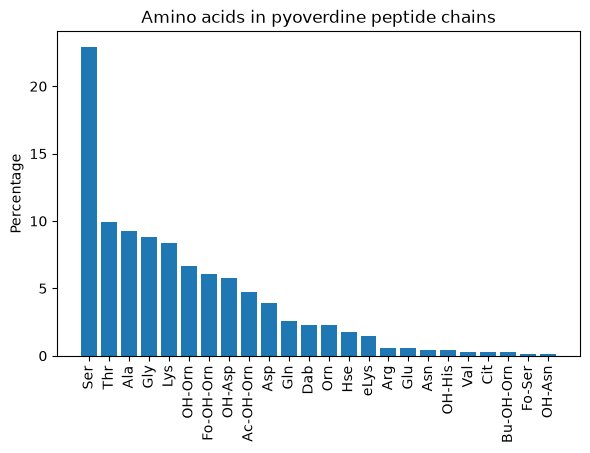

In [8]:
combined_percentage = combined / combined_sum * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(combined_percentage.index, combined_percentage.values)
ax.set_title("Amino acids in pyoverdine peptide chains")
ax.set_ylabel("Percentage")
fig.tight_layout()
plt.xticks(rotation=90)
plt.show()

L- versus D-amino acid totals

In [9]:
from scipy.stats import binomtest

stereo_totals = res["stereo"].value_counts().reindex(["L", "D", "unspecified"], fill_value=0)
L_total = stereo_totals["L"]
D_total = stereo_totals["D"]
LD_n = L_total + D_total

print (f"The percentage of L-amino acids is {L_total / (LD_n) * 100:.3}%")

result = binomtest(L_total, n=LD_n, p=0.5, alternative='two-sided')

print (f'There are {LD_n} amino acids in which the L- vs D-stereochemistry was determined.\n')
print (f'A {result.alternative} binomial test indicates that the proportion of L-amino acids ({L_total} out of {LD_n}, or {L_total/LD_n:.1%}) is significantly greater than 50% (p={result.pvalue:.2g})')


The percentage of L-amino acids is 60.8%
There are 385 amino acids in which the L- vs D-stereochemistry was determined.

A two-sided binomial test indicates that the proportion of L-amino acids (234 out of 385, or 60.8%) is significantly greater than 50% (p=2.7e-05)


Performed a Fisher's test for 2x2 contingency tables comparing the counts of L- vs D- for each amino acid vs the counts for all amino acids. Performed a correction for multiple hypothesis testing and graphed.

In [10]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
import numpy as np

MIN_COUNT = 5

# L/D counts per residue
ss = (pd.crosstab(res["residue"], res["stereo"])
        .reindex(columns=["L", "D"], fill_value=0))
ss = ss[ss.sum(axis=1) > 0]
ss = ss.loc[ss.sum(axis=1).sort_values(ascending=False).index]

# Group rare residues
is_common = (ss["L"] >= MIN_COUNT) | (ss["D"] >= MIN_COUNT)
common_aa = ss[is_common].copy()
rare = ss[~is_common]
if len(rare):
    common_aa.loc["Rare"] = rare.sum()

# Fisher's exact test: each residue vs all other residues
total_L, total_D = common_aa["L"].sum(), common_aa["D"].sum()
rows = []
for aa, (a, b) in common_aa[["L", "D"]].iterrows():
    c, d = total_L - a, total_D - b
    odds, p = fisher_exact([[a, b], [c, d]])
    rows.append({"residue": aa, "L": a, "D": b, "odds_ratio": odds, "p": p})
results = pd.DataFrame(rows).set_index("residue")
results

# Benjamini-Hochberg adjustment
reject, p_adj, _, _ = multipletests(results["p"], alpha=0.05, method="fdr_bh")
results["p_adj"] = p_adj
results["significant"] = reject
results["enriched_for"] = np.where(results["odds_ratio"] > 1, "L", "D")
print(results.round(4), "\n")

sig = results[results["significant"]]
if sig.empty:
    print("No amino acids differed significantly from the expected L:D proportion (FDR < 0.05).")
else:
    parts = [f"{aa} ({row.enriched_for}-enriched, adjusted p = {row.p_adj:.2g})"
             for aa, row in sig.iterrows()]
    print("The following amino acids differed significantly from the expected L:D proportion: "
          + "; ".join(parts) + ".")

p_adj

            L   D  odds_ratio       p   p_adj  significant enriched_for
residue                                                                
Ser        40  47      0.4562  0.0017  0.0242         True            D
Thr        33  13      1.7428  0.1107  0.1384        False            L
Lys        29  10      1.9946  0.0832  0.1310        False            L
Ala        17  17      0.6175  0.1997  0.2305        False            D
Fo-OH-Orn  17  12      0.9075  0.8445  0.8445        False            D
OH-Orn     23   5      3.1829  0.0160  0.0600        False            L
OH-Asp      8  17      0.2790  0.0048  0.0242         True            D
Ac-OH-Orn   8  13      0.3758  0.0376  0.0736        False            D
Asp        16   1     11.0092  0.0038  0.0242         True            L
Gln         4   9      0.2744  0.0392  0.0736        False            D
Dab         9   1      6.0000  0.0961  0.1310        False            L
Hse         8   1      5.3097  0.0957  0.1310        False      

array([0.02420047, 0.13841899, 0.13103949, 0.23045999, 0.84449978,
       0.06003331, 0.02420047, 0.07356607, 0.02420047, 0.07356607,
       0.13103949, 0.13103949, 0.06184749, 0.06184749, 0.81158671])

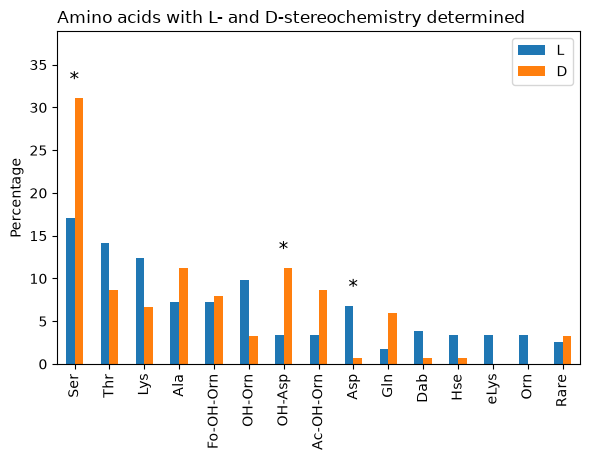

In [11]:
# Percentage of all L (or D) residues that each amino acid accounts for
common_pc = pd.DataFrame({
    "L": common_aa["L"] / total_L * 100,
    "D": common_aa["D"] / total_D * 100,
})

fig, ax = plt.subplots(figsize=(6, 4.7))
common_pc.plot(kind="bar", ax=ax)
ax.set_title("Amino acids with L- and D-stereochemistry determined", loc="left")
ax.set_ylabel("Percentage")
ax.set_xlabel(None)
def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

pad = common_pc.values.max() * 0.03
for i, aa in enumerate(common_pc.index):
    s = stars(results.loc[aa, "p_adj"])
    if s:
        ax.text(i, common_pc.loc[aa].max() + pad, s, ha="center", va="bottom", fontsize=14)

ax.set_ylim(0, common_pc.values.max() * 1.25)
fig.tight_layout()
plt.show()

## Graphs based on groupings

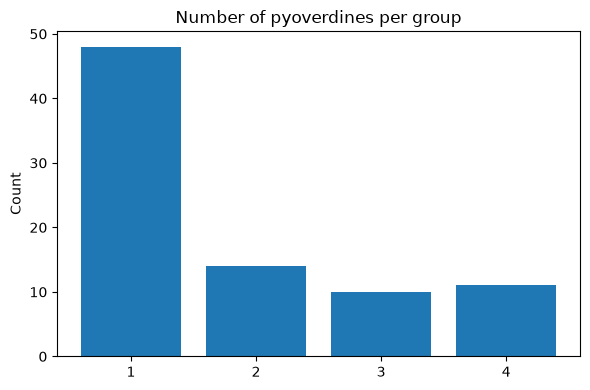

In [12]:
groups = pyoverdine_lib["group"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(groups.index.astype(str), groups.values)
ax.set_title("Number of pyoverdines per group")
ax.set_ylabel("Count")
fig.tight_layout()
plt.show()

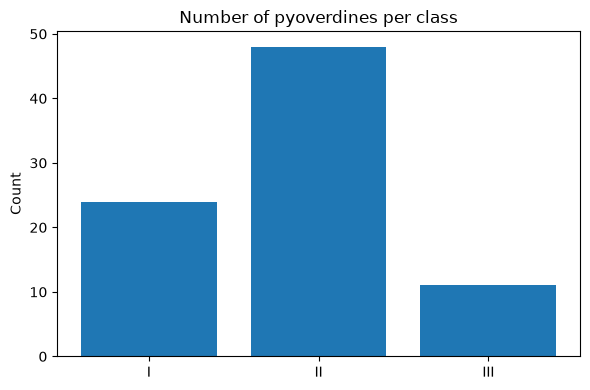

In [14]:
classes = pyoverdine_lib["class"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(classes.index, classes.values)
ax.set_title("Number of pyoverdines per class")
ax.set_ylabel("Count")
fig.tight_layout()
plt.show()